# GRU forecasting for scintillation real/imaginary time series

This notebook does:
1. Dataset download
2. Input and residual target definition from true intensity plus estimated scintillation phase, excluding loss-of-lock signals
3. Simple GRU model definition and training with early stopping
4. Direct forecast metrics
5. Sliding-window backpropagation using the GRU forecast and field metrics against the true refractive field


## 1. Dataset Download

In [1]:
from pathlib import Path
import ctypes
import json
import os
import sysconfig

os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"

site_packages = Path(sysconfig.get_paths()["purelib"])
nvidia_root = site_packages / "nvidia"
for package_name in [
    "cuda_runtime",
    "cuda_nvrtc",
    "nvjitlink",
    "cublas",
    "cufft",
    "curand",
    "cusparse",
    "cusolver",
    "cudnn",
    "nccl",
    "cuda_cupti",
]:
    for lib_path in sorted((nvidia_root / package_name / "lib").glob("*.so*")):
        ctypes.CDLL(str(lib_path), mode=ctypes.RTLD_GLOBAL)

import kagglehub
from loguru import logger
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import fft, ifft
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_dir = project_root / "outputs" / "gru_backpropagation"
output_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "font.size": 12,
        "axes.titlesize": 16,
        "axes.labelsize": 13,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 9,
        "lines.linewidth": 1.7,
        "lines.markersize": 5,
        "figure.dpi": 120,
    }
)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
tf.config.set_soft_device_placement(True)
DEVICE = "/GPU:0"

print("Physical GPUs:", gpus)
print("Training device:", DEVICE)

np.random.seed(42)
tf.random.set_seed(42)

path = kagglehub.dataset_download("rodrigodlf/backpropagation/versions/5")
print("Path to dataset files:", path)

/home/felix/github/real-time-bp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1778859384.223121 1060138 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778859384.252406 1060138 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778859384.876414 1060138 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to flo

Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training device: /GPU:0
Path to dataset files: /home/felix/.cache/kagglehub/datasets/rodrigodlf/backpropagation/versions/5


## 2. Input and Target Definition

In [2]:
TRACKED_PATH = Path(path) / "tracked"
X_raw = np.load(TRACKED_PATH / "X_main.npy")
y_df = pd.read_csv(TRACKED_PATH / "y_main.csv")
meta = json.loads((TRACKED_PATH / "meta_main.json").read_text())

channel_labels = meta["channel_labels"]
required_channels = [
    "intensity_L1",
    "true_intensity_L1",
    "scint_phase_L1",
    "postprop_phase_L1",
    "refractive_phase_L1",
]
missing_channels = [name for name in required_channels if name not in channel_labels]
if missing_channels:
    raise ValueError(f"Dataset is missing required channels: {missing_channels}")
if "loss_of_lock_L1" not in y_df.columns:
    raise ValueError("Dataset is missing required column: loss_of_lock_L1")

intensity_idx = channel_labels.index("intensity_L1")
true_intensity_idx = channel_labels.index("true_intensity_L1")
scint_phase_idx = channel_labels.index("scint_phase_L1")
postprop_phase_idx = channel_labels.index("postprop_phase_L1")
refractive_phase_idx = channel_labels.index("refractive_phase_L1")

intensity = np.maximum(X_raw[:, :, intensity_idx].astype("float32"), 0.0)
true_intensity = np.maximum(X_raw[:, :, true_intensity_idx].astype("float32"), 0.0)
scint_phase = X_raw[:, :, scint_phase_idx].astype("float32")
postprop_phase = X_raw[:, :, postprop_phase_idx].astype("float32")
refractive_phase = X_raw[:, :, refractive_phase_idx].astype("float32")

# Supervised target: estimated scintillation phase with the newly available true intensity.
estimated_scint_field = np.sqrt(true_intensity).astype("float32") * np.exp(1j * scint_phase)
series = np.stack([np.real(estimated_scint_field), np.imag(estimated_scint_field)], axis=-1).astype("float32")

# Carrier tracking loop estimate, using the tracking-loop intensity and scintillation phase.
tracking_scint_field = np.sqrt(intensity).astype("float32") * np.exp(1j * scint_phase)
tracking_scint_series = np.stack([np.real(tracking_scint_field), np.imag(tracking_scint_field)], axis=-1).astype("float32")

# References for downstream backpropagation quality checks.
true_postprop_series = (np.sqrt(true_intensity).astype("float32") * np.exp(1j * postprop_phase)).astype("complex64")
screen_series = np.exp(1j * refractive_phase).astype("complex64")

loss_of_lock = (
    y_df["loss_of_lock_L1"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "yes", "y"])
    .to_numpy()
)
valid_signal_idx = np.flatnonzero(~loss_of_lock)

if len(valid_signal_idx) == 0:
    raise ValueError("No lock-valid signals remain after filtering loss_of_lock_L1.")

dt = float(meta["t_samp_sec"])

print("X_raw shape:", X_raw.shape)
print("series shape:", series.shape)
print("y shape:", y_df.shape)
print("lock-valid signals:", len(valid_signal_idx))
print("excluded loss-of-lock signals:", int(loss_of_lock.sum()))
print("channels used for GRU targets:", channel_labels[true_intensity_idx], channel_labels[scint_phase_idx])
print("carrier tracking estimate channels:", channel_labels[intensity_idx], channel_labels[scint_phase_idx])
print("backpropagation references:", channel_labels[postprop_phase_idx], channel_labels[refractive_phase_idx])
print("sample interval dt [s]:", dt)

del X_raw, intensity, true_intensity, scint_phase, postprop_phase, refractive_phase, estimated_scint_field, tracking_scint_field


X_raw shape: (10000, 15000, 5)
series shape: (10000, 15000, 2)
y shape: (10000, 20)
lock-valid signals: 6726
excluded loss-of-lock signals: 3274
channels used for GRU targets: true_intensity_L1 scint_phase_L1
carrier tracking estimate channels: intensity_L1 scint_phase_L1
backpropagation references: postprop_phase_L1 refractive_phase_L1
sample interval dt [s]: 0.02


In [3]:
n_realizations = len(valid_signal_idx)
rng = np.random.default_rng(42)
realization_order = rng.permutation(valid_signal_idx)

n_train = int(0.70 * n_realizations)
n_val = int(0.15 * n_realizations)

train_idx = realization_order[:n_train]
val_idx = realization_order[n_train : n_train + n_val]
test_idx = realization_order[n_train + n_val :]

train_mean = series[train_idx].mean(axis=(0, 1), keepdims=True)
train_std = series[train_idx].std(axis=(0, 1), keepdims=True)

print("lock-valid realizations:", n_realizations)
print("train/validation/test realizations:", len(train_idx), len(val_idx), len(test_idx))
print("train mean:", train_mean.ravel())
print("train std:", train_std.ravel())


lock-valid realizations: 6726
train/validation/test realizations: 4708 1008 1010
train mean: [ 0.0050902  -0.00090245]
train std: [0.6323643 0.63123  ]


In [4]:
M = 1024
half = M // 2
future_context = M - half - 1
L = 64
window_stride = 512  # samples between adjacent GRU training/evaluation centers
backprop_stride = 1  # dense sliding-window centers for backpropagation

input_len = half + L + 1
target_len = future_context - L
centers = np.arange(half, series.shape[1] - future_context, window_stride)
backprop_centers = np.arange(half, series.shape[1] - future_context, backprop_stride)

print("M:", M)
print("half:", half)
print("future_context:", future_context)
print("latency L:", L)
print("input shape per window:", (input_len, 2))
print("target shape per window:", (target_len, 2))
print("GRU windows per realization:", len(centers))
print("backpropagation windows per realization:", len(backprop_centers))

M: 1024
half: 512
future_context: 511
latency L: 64
input shape per window: (577, 2)
target shape per window: (447, 2)
GRU windows per realization: 28
backpropagation windows per realization: 13977


In [5]:
BATCH_SIZE = 128
if BATCH_SIZE < 1:
    raise ValueError("BATCH_SIZE must be at least 1.")

norm_mean = train_mean.squeeze().astype("float32")
norm_std = train_std.squeeze().astype("float32")


class WindowSequence(keras.utils.Sequence):
    def __init__(self, realization_indices, window_centers=centers, batch_size=BATCH_SIZE, shuffle=False):
        self.realization_indices = np.asarray(realization_indices)
        self.centers = np.asarray(window_centers)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.n_windows = len(self.realization_indices) * len(self.centers)
        self.order = np.arange(self.n_windows)
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(self.n_windows / self.batch_size))

    def __getitem__(self, idx):
        batch_positions = self.order[idx * self.batch_size : (idx + 1) * self.batch_size]
        X = np.empty((len(batch_positions), input_len, 2), dtype="float32")
        y = np.empty((len(batch_positions), target_len, 2), dtype="float32")

        for row, window_position in enumerate(batch_positions):
            realization_position = window_position // len(self.centers)
            center_position = window_position % len(self.centers)
            realization_idx = self.realization_indices[realization_position]
            k = self.centers[center_position]
            anchor = series[realization_idx, k + L]
            future = series[realization_idx, k + L + 1 : k + future_context + 1]
            X[row] = (series[realization_idx, k - half : k + L + 1] - norm_mean) / norm_std
            y[row] = (future - anchor) / norm_std

        return X, y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.order)


train_seq = WindowSequence(train_idx, batch_size=BATCH_SIZE, shuffle=True)
val_seq = WindowSequence(val_idx, batch_size=BATCH_SIZE)
test_seq = WindowSequence(test_idx, batch_size=BATCH_SIZE)

print("train windows:", train_seq.n_windows)
print("validation windows:", val_seq.n_windows)
print("test windows:", test_seq.n_windows)
print("GRU target: future residual relative to the last observed sample")
print("batch size:", BATCH_SIZE)

train windows: 131824
validation windows: 28224
test windows: 28280
GRU target: future residual relative to the last observed sample
batch size: 128


## 3. Simple GRU Model Definition and Training

In [6]:
with tf.device(DEVICE):
    model = keras.Sequential(
        [
            keras.Input(shape=(input_len, 2)),
            layers.LayerNormalization(),
            layers.GRU(64, return_sequences=True),
            layers.Dropout(0.1),
            layers.GRU(64),
            layers.Dropout(0.1),
            layers.Dense(128, activation="relu"),
            layers.Dense(target_len * 2),
            layers.Reshape((target_len, 2)),
        ]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
        loss="mse",
        metrics=["mae"],
    )

model.summary()

I0000 00:00:1778859413.211070 1060138 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1778859413.212197 1060138 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5320 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer_normalization             │ (None, 577, 2)         │             4 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 577, 64)        │        13,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 577, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 894)            │       115,326 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 447, 2)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161,666 (631.51 KB)

 Trainable params: 161,666 (631.51 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    min_delta=1e-4,
    restore_best_weights=True,
)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-5,
    verbose=1,
)

with tf.device(DEVICE):
    history = model.fit(
        train_seq,
        validation_data=val_seq,
        epochs=100,
        callbacks=[early_stopping, reduce_lr],
    )

Epoch 1/100


/home/felix/github/real-time-bp/.venv/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1778859413.836328 1060138 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1778859415.137347 1060585 cuda_dnn.cc:461] Loaded cuDNN version 92200


1030/1030 ━━━━━━━━━━━━━━━━━━━━ 64s 60ms/step - loss: 1.7797 - mae: 1.0531 - val_loss: 1.7609 - val_mae: 1.0483 - learning_rate: 0.0010
Epoch 2/100
1030/1030 ━━━━━━━━━━━━━━━━━━━━ 37s 36ms/step - loss: 1.7641 - mae: 1.0487 - val_loss: 1.7551 - val_mae: 1.0468 - learning_rate: 0.0010
Epoch 3/100
1030/1030 ━━━━━━━━━━━━━━━━━━━━ 37s 36ms/step - loss: 1.7562 - mae: 1.0462 - val_loss: 1.7430 - val_mae: 1.0426 - learning_rate: 0.0010
Epoch 4/100
1030/1030 ━━━━━━━━━━━━━━━━━━━━ 38s 36ms/step - loss: 1.7505 - mae: 1.0445 - val_loss: 1.7415 - val_mae: 1.0422 - learning_rate: 0.0010
Epoch 5/100
1030/1030 ━━━━━━━━━━━━━━━━━━━━ 37s 36ms/step - loss: 1.7452 - mae: 1.0430 - val_loss: 1.7397 - val_mae: 1.0414 - learning_rate: 0.0010
Epoch 6/100
1030/1030 ━━━━━━━━━━━━━━━━━━━━ 37s 36ms/step - loss: 1.7413 - mae: 1.0418 - val_loss: 1.7325 - val_mae: 1.0399 - learning_rate: 0.0010
Epoch 7/100
1030/1030 ━━━━━━━━━━━━━━━━━━━━ 38s 36ms/step - loss: 1.7319 - mae: 1.0390 - val_loss: 1.7150 - val_mae: 1.0350 - learn

## 4. Visualization of Metrics and an Example

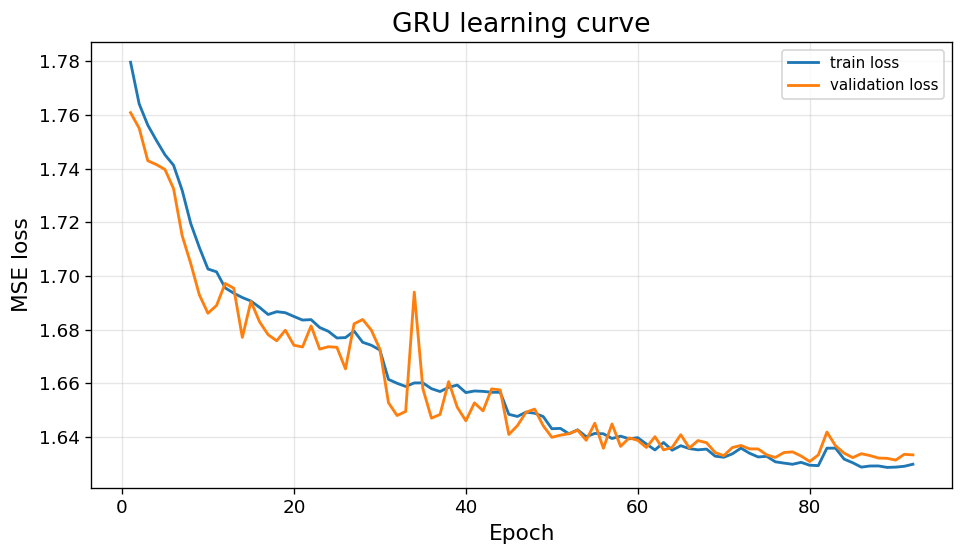

In [8]:
history_df = pd.DataFrame(history.history)

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.plot(history_df.index + 1, history_df["loss"], label="train loss")
ax.plot(history_df.index + 1, history_df["val_loss"], label="validation loss")
ax.set_title("GRU learning curve")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout(pad=1.1)
plt.show()

In [9]:
with tf.device(DEVICE):
    y_pred = model.predict(test_seq)

y_test = np.concatenate([test_seq[i][1] for i in range(len(test_seq))], axis=0)

test_window_anchors = np.empty((len(test_idx) * len(centers), 2), dtype="float32")
row = 0
for realization_idx in test_idx:
    for k in centers:
        test_window_anchors[row] = series[int(realization_idx), int(k) + L]
        row += 1

y_test_original = test_window_anchors[:, None, :] + y_test * train_std.squeeze()
y_pred_original = test_window_anchors[:, None, :] + y_pred * train_std.squeeze()

y_true_flat = y_test_original.reshape(-1)
y_pred_flat = y_pred_original.reshape(-1)

rmse = np.sqrt(np.mean((y_pred_flat - y_true_flat) ** 2))
mae = np.mean(np.abs(y_pred_flat - y_true_flat))
mape = 100 * np.mean(np.abs((y_pred_flat - y_true_flat) / (np.abs(y_true_flat) + 1e-8)))
r2 = 1 - np.sum((y_true_flat - y_pred_flat) ** 2) / np.sum((y_true_flat - y_true_flat.mean()) ** 2)

metrics_df = pd.DataFrame(
    {
        "metric": ["RMSE", "MAE", "MAPE", "R2"],
        "value": [rmse, mae, mape, r2],
    }
)
metrics_df

221/221 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step


,metric,value
0,RMSE,0.807663
1,MAE,0.637458
2,MAPE,906.668823
3,R2,-0.304407


In [10]:
def compute_field_metrics(psi_ref, psi_hat, idx):
    idx = idx & np.isfinite(psi_hat) & np.isfinite(psi_ref)
    if not np.any(idx):
        return {
            "num_valid_samples": 0,
            "field_rel_error": np.nan,
            "amp_rmse": np.nan,
            "phase_rmse_rad": np.nan,
        }

    field_rel_error = np.linalg.norm(psi_hat[idx] - psi_ref[idx]) / np.linalg.norm(psi_ref[idx])
    amp_rmse = np.sqrt(np.mean((np.abs(psi_hat[idx]) - np.abs(psi_ref[idx])) ** 2))
    phase_rmse = np.sqrt(np.mean(np.angle(psi_hat[idx] * np.conj(psi_ref[idx])) ** 2))
    return {
        "num_valid_samples": int(np.sum(idx)),
        "field_rel_error": float(field_rel_error),
        "amp_rmse": float(amp_rmse),
        "phase_rmse_rad": float(phase_rmse),
    }


def backprop_kernel(block_len, rho_over_v):
    f_block = np.fft.fftfreq(block_len, d=dt)
    return np.exp(0.5j * (2 * np.pi * f_block * rho_over_v) ** 2)


def backprop_center_value(block, rho_over_v):
    H_block = backprop_kernel(len(block), rho_over_v)
    return ifft(fft(block) * H_block)[len(block) // 2]


def backprop_center_values(blocks, H_block):
    return ifft(fft(blocks, axis=1) * H_block[None, :], axis=1)[:, blocks.shape[1] // 2]


def unwrap_finite_phase(z):
    phase = np.full(len(z), np.nan, dtype=float)
    idx = np.isfinite(z)
    phase[idx] = np.unwrap(np.angle(z[idx]))
    return phase


def median_align_to_reference(phase, reference, idx):
    aligned = phase.copy()
    valid = idx & np.isfinite(phase) & np.isfinite(reference)
    if np.any(valid):
        aligned = aligned - np.median(aligned[valid] - reference[valid])
    return aligned


def compute_backpropagation_fields(realization_indices, window_centers, chunk_size=512, log_every_chunks=10):
    realization_indices = np.asarray(realization_indices)
    window_centers = np.asarray(window_centers)
    n_windows = len(realization_indices) * len(window_centers)

    psi_ref = np.empty(n_windows, dtype="complex64")
    psi_gru_forecast = np.empty(n_windows, dtype="complex64")
    psi_full_estimated = np.empty(n_windows, dtype="complex64")
    psi_true_postprop = np.empty(n_windows, dtype="complex64")

    logger.info(
        "Starting dense backpropagation: {} realizations, {} centers each, {} total windows, chunk_size={}",
        len(realization_indices),
        len(window_centers),
        n_windows,
        chunk_size,
    )

    n_chunks = int(np.ceil(len(window_centers) / chunk_size))
    for realization_position, realization_idx in enumerate(realization_indices):
        realization_idx = int(realization_idx)
        rho_over_v = float(y_df.iloc[realization_idx]["rhof_veff_ratio_L1"])
        H_block = backprop_kernel(M, rho_over_v)
        realization_offset = realization_position * len(window_centers)
        logger.info(
            "Backpropagation realization {}/{}: idx={}, rho_over_v={:.6g}",
            realization_position + 1,
            len(realization_indices),
            realization_idx,
            rho_over_v,
        )

        for chunk_position, chunk_start in enumerate(range(0, len(window_centers), chunk_size)):
            chunk_stop = min(chunk_start + chunk_size, len(window_centers))
            chunk_centers = window_centers[chunk_start:chunk_stop]
            chunk_len = len(chunk_centers)

            X_batch = np.empty((chunk_len, input_len, 2), dtype="float32")
            for row, k in enumerate(chunk_centers):
                k = int(k)
                X_batch[row] = (series[realization_idx, k - half : k + L + 1] - norm_mean) / norm_std

            with tf.device(DEVICE):
                pred_residual_batch = model(X_batch, training=False).numpy() * norm_std

            forecast_blocks = np.empty((chunk_len, M), dtype="complex64")
            full_estimated_blocks = np.empty((chunk_len, M), dtype="complex64")
            true_postprop_blocks = np.empty((chunk_len, M), dtype="complex64")
            out_start = realization_offset + chunk_start

            for row, k in enumerate(chunk_centers):
                k = int(k)
                start = k - half
                observed_stop = k + L + 1
                stop = k + future_context + 1

                observed_prefix = series[realization_idx, start:observed_stop, 0] + 1j * series[realization_idx, start:observed_stop, 1]
                forecast_tail_values = series[realization_idx, observed_stop - 1] + pred_residual_batch[row]
                forecast_tail = forecast_tail_values[:, 0] + 1j * forecast_tail_values[:, 1]
                forecast_blocks[row] = np.concatenate([observed_prefix, forecast_tail])
                full_estimated_blocks[row] = series[realization_idx, start:stop, 0] + 1j * series[realization_idx, start:stop, 1]
                true_postprop_blocks[row] = true_postprop_series[realization_idx, start:stop]
                psi_ref[out_start + row] = screen_series[realization_idx, k]

            out_slice = slice(out_start, out_start + chunk_len)
            psi_gru_forecast[out_slice] = backprop_center_values(forecast_blocks, H_block)
            psi_full_estimated[out_slice] = backprop_center_values(full_estimated_blocks, H_block)
            psi_true_postprop[out_slice] = backprop_center_values(true_postprop_blocks, H_block)

            if (chunk_position + 1) % log_every_chunks == 0 or chunk_position + 1 == n_chunks:
                logger.info(
                    "  realization idx={} chunk {}/{} complete: centers {}-{}",
                    realization_idx,
                    chunk_position + 1,
                    n_chunks,
                    int(chunk_centers[0]),
                    int(chunk_centers[-1]),
                )

    logger.info("Finished dense backpropagation for {} windows", n_windows)

    return psi_ref, psi_gru_forecast, psi_full_estimated, psi_true_postprop


psi_ref, psi_gru_forecast, psi_full_estimated, psi_true_postprop = compute_backpropagation_fields(
    test_idx,
    backprop_centers,
)

valid_bp_idx = np.ones(len(psi_ref), dtype=bool)
backprop_metrics_df = pd.DataFrame(
    [
        {
            "method": "GRU forecasted estimated scintillation",
            "block_len": M,
            "latency_samples": L,
            "backprop_stride_samples": backprop_stride,
            "forecast_steps": target_len,
            **compute_field_metrics(psi_ref, psi_gru_forecast, valid_bp_idx),
        },
        {
            "method": "Full estimated scintillation window",
            "block_len": M,
            "latency_samples": future_context,
            "backprop_stride_samples": backprop_stride,
            "forecast_steps": 0,
            **compute_field_metrics(psi_ref, psi_full_estimated, valid_bp_idx),
        },
        {
            "method": "Exact postpropagated window",
            "block_len": M,
            "latency_samples": future_context,
            "backprop_stride_samples": backprop_stride,
            "forecast_steps": 0,
            **compute_field_metrics(psi_ref, psi_true_postprop, valid_bp_idx),
        },
    ]
)
backprop_metrics_df.to_csv(output_dir / "gru_sliding_window_backpropagation_metrics.csv", index=False)
backprop_metrics_df


2026-05-15 13:34:57.229 | INFO     | __main__:compute_backpropagation_fields:61 - Starting dense backpropagation: 1010 realizations, 13977 centers each, 14116770 total windows, chunk_size=512
2026-05-15 13:34:57.230 | INFO     | __main__:compute_backpropagation_fields:75 - Backpropagation realization 1/1010: idx=2289, rho_over_v=0.576032
2026-05-15 13:34:57.789 | INFO     | __main__:compute_backpropagation_fields:121 -   realization idx=2289 chunk 10/28 complete: centers 5120-5631
2026-05-15 13:34:58.309 | INFO     | __main__:compute_backpropagation_fields:121 -   realization idx=2289 chunk 20/28 complete: centers 10240-10751
2026-05-15 13:34:58.743 | INFO     | __main__:compute_backpropagation_fields:121 -   realization idx=2289 chunk 28/28 complete: centers 14336-14488
2026-05-15 13:34:58.744 | INFO     | __main__:compute_backpropagation_fields:75 - Backpropagation realization 2/1010: idx=2962, rho_over_v=1.37328
2026-05-15 13:34:59.286 | INFO     | __main__:compute_backpropagation_f

,method,block_len,latency_samples,backprop_stride_samples,forecast_steps,num_valid_samples,field_rel_error,amp_rmse,phase_rmse_rad
0,GRU forecasted estimated scintillation,1024,64,1,447,14116770,0.432364,0.301819,0.464738
1,Full estimated scintillation window,1024,511,1,0,14116770,0.219442,0.135053,0.186514
2,Exact postpropagated window,1024,511,1,0,14116770,0.204943,0.123556,0.176430


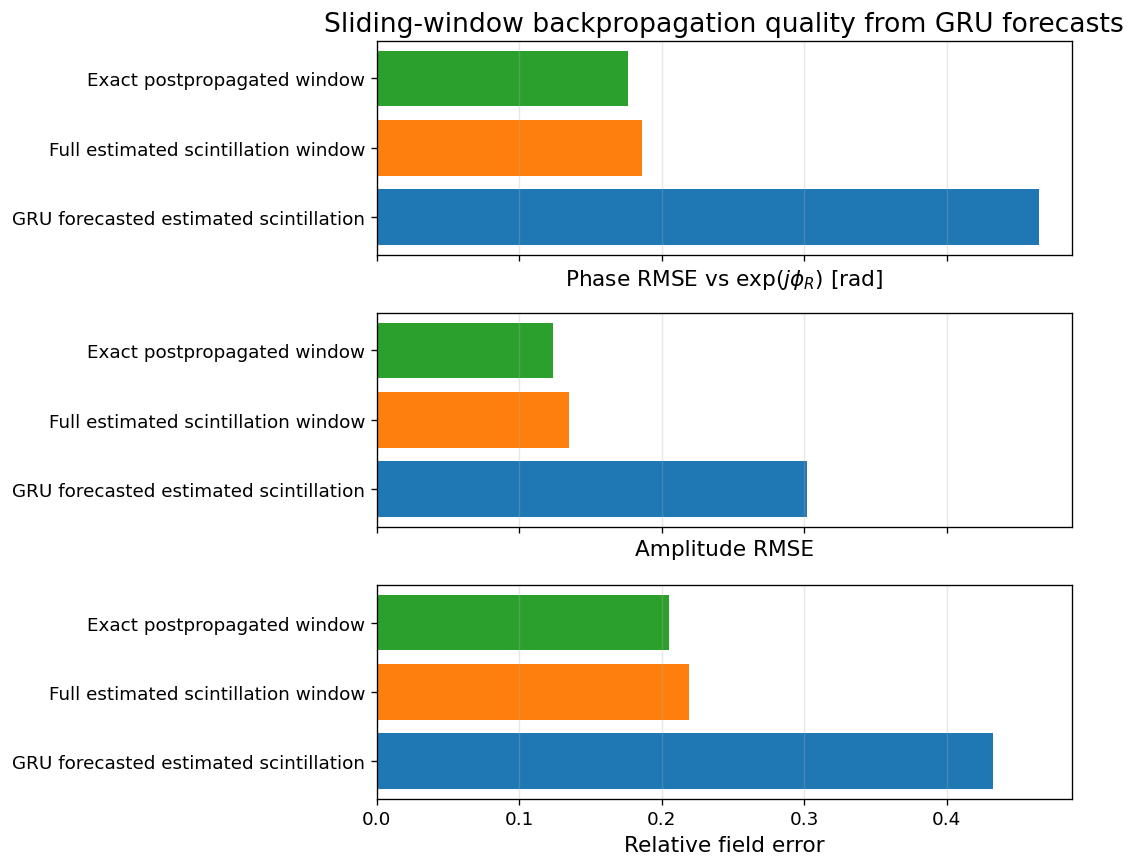

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(9.2, 7.4), sharex=True)
for ax, metric, ylabel in [
    (axes[0], "phase_rmse_rad", r"Phase RMSE vs $\exp(j\phi_R)$ [rad]"),
    (axes[1], "amp_rmse", "Amplitude RMSE"),
    (axes[2], "field_rel_error", "Relative field error"),
]:
    ax.barh(backprop_metrics_df["method"], backprop_metrics_df[metric], color=["tab:blue", "tab:orange", "tab:green"])
    ax.set_xlabel(ylabel)
    ax.grid(True, axis="x", alpha=0.3)
axes[0].set_title("Sliding-window backpropagation quality from GRU forecasts")
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "gru_sliding_window_backpropagation_metrics.png", dpi=300)
plt.show()


2026-05-15 13:59:16.833 | INFO     | __main__:compute_backpropagation_fields:61 - Starting dense backpropagation: 1 realizations, 13977 centers each, 13977 total windows, chunk_size=512
2026-05-15 13:59:16.837 | INFO     | __main__:compute_backpropagation_fields:75 - Backpropagation realization 1/1: idx=2962, rho_over_v=1.37328
2026-05-15 13:59:17.358 | INFO     | __main__:compute_backpropagation_fields:121 -   realization idx=2962 chunk 10/28 complete: centers 5120-5631
2026-05-15 13:59:17.864 | INFO     | __main__:compute_backpropagation_fields:121 -   realization idx=2962 chunk 20/28 complete: centers 10240-10751
2026-05-15 13:59:18.250 | INFO     | __main__:compute_backpropagation_fields:121 -   realization idx=2962 chunk 28/28 complete: centers 14336-14488
2026-05-15 13:59:18.251 | INFO     | __main__:compute_backpropagation_fields:130 - Finished dense backpropagation for 13977 windows


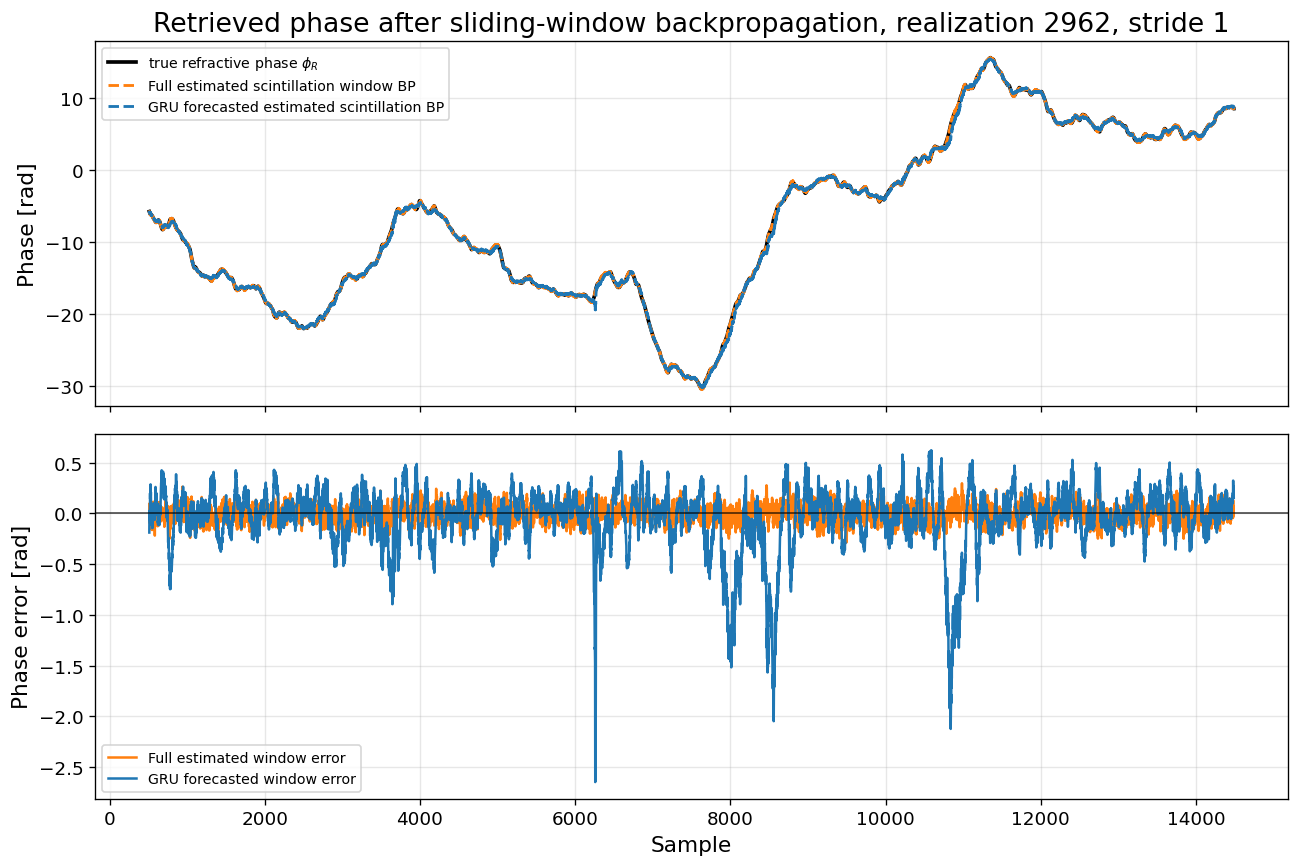

In [12]:
example_bp_realization_idx = int(test_idx[1])
phase_example_stride = backprop_stride
example_bp_centers = backprop_centers

_, psi_gru_example, psi_full_estimated_example, _ = compute_backpropagation_fields(
    [example_bp_realization_idx],
    example_bp_centers,
)

phase_ref_full = np.unwrap(np.angle(screen_series[example_bp_realization_idx]))
phase_gru_full = np.full(series.shape[1], np.nan, dtype=float)
phase_full_estimated_full = np.full(series.shape[1], np.nan, dtype=float)

phase_gru_full[example_bp_centers] = unwrap_finite_phase(psi_gru_example)
phase_full_estimated_full[example_bp_centers] = unwrap_finite_phase(psi_full_estimated_example)

plot_idx = np.zeros(series.shape[1], dtype=bool)
plot_idx[example_bp_centers] = True
phase_gru_aligned = median_align_to_reference(phase_gru_full, phase_ref_full, plot_idx)
phase_full_estimated_aligned = median_align_to_reference(phase_full_estimated_full, phase_ref_full, plot_idx)

phase_example_df = pd.DataFrame(
    {
        "sample": example_bp_centers,
        "refractive_phase_rad": phase_ref_full[example_bp_centers],
        "gru_forecast_backprop_phase_rad": phase_gru_aligned[example_bp_centers],
        "full_estimated_backprop_phase_rad": phase_full_estimated_aligned[example_bp_centers],
        "gru_forecast_phase_error_rad": phase_gru_aligned[example_bp_centers] - phase_ref_full[example_bp_centers],
        "full_estimated_phase_error_rad": phase_full_estimated_aligned[example_bp_centers] - phase_ref_full[example_bp_centers],
    }
)
phase_example_df.to_csv(output_dir / "gru_backpropagated_phase_example.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(11.0, 7.4), sharex=True)
axes[0].plot(example_bp_centers, phase_ref_full[example_bp_centers], "k", linewidth=2.2, label=r"true refractive phase $\phi_R$")
axes[0].plot(
    example_bp_centers,
    phase_full_estimated_aligned[example_bp_centers],
    "--",
    color="tab:orange",
    linewidth=1.7,
    label="Full estimated scintillation window BP",
)
axes[0].plot(
    example_bp_centers,
    phase_gru_aligned[example_bp_centers],
    "--",
    color="tab:blue",
    linewidth=1.7,
    label="GRU forecasted estimated scintillation BP",
)

axes[1].plot(
    example_bp_centers,
    phase_full_estimated_aligned[example_bp_centers] - phase_ref_full[example_bp_centers],
    color="tab:orange",
    linewidth=1.5,
    label="Full estimated window error",
)
axes[1].plot(
    example_bp_centers,
    phase_gru_aligned[example_bp_centers] - phase_ref_full[example_bp_centers],
    color="tab:blue",
    linewidth=1.5,
    label="GRU forecasted window error",
)
axes[1].axhline(0, color="k", linewidth=1.0, alpha=0.7)

axes[0].set_ylabel("Phase [rad]")
axes[0].set_title(
    f"Retrieved phase after sliding-window backpropagation, realization {example_bp_realization_idx}, stride {phase_example_stride}"
)
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Phase error [rad]")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=1, fontsize=8.5)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "gru_backpropagated_phase_example.png", dpi=300)
plt.show()


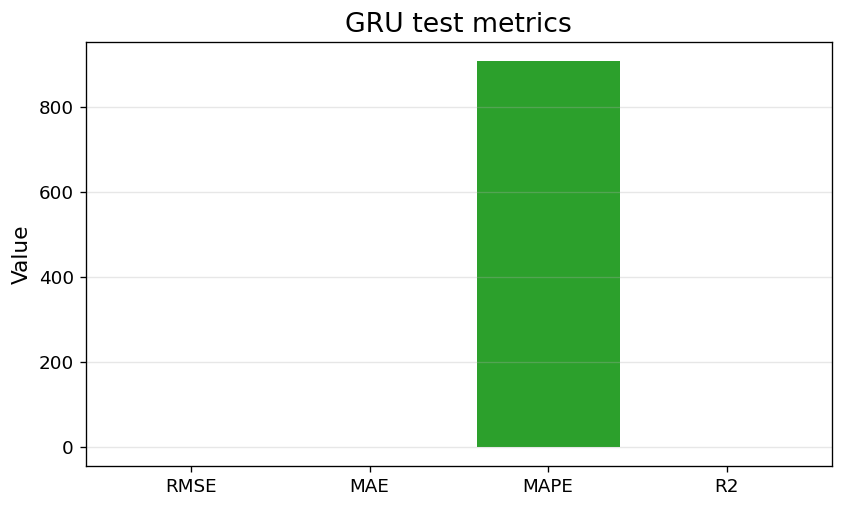

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.bar(metrics_df["metric"], metrics_df["value"], color=["tab:blue", "tab:orange", "tab:green", "tab:red"])
ax.set_title("GRU test metrics")
ax.set_ylabel("Value")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout(pad=1.1)
plt.show()

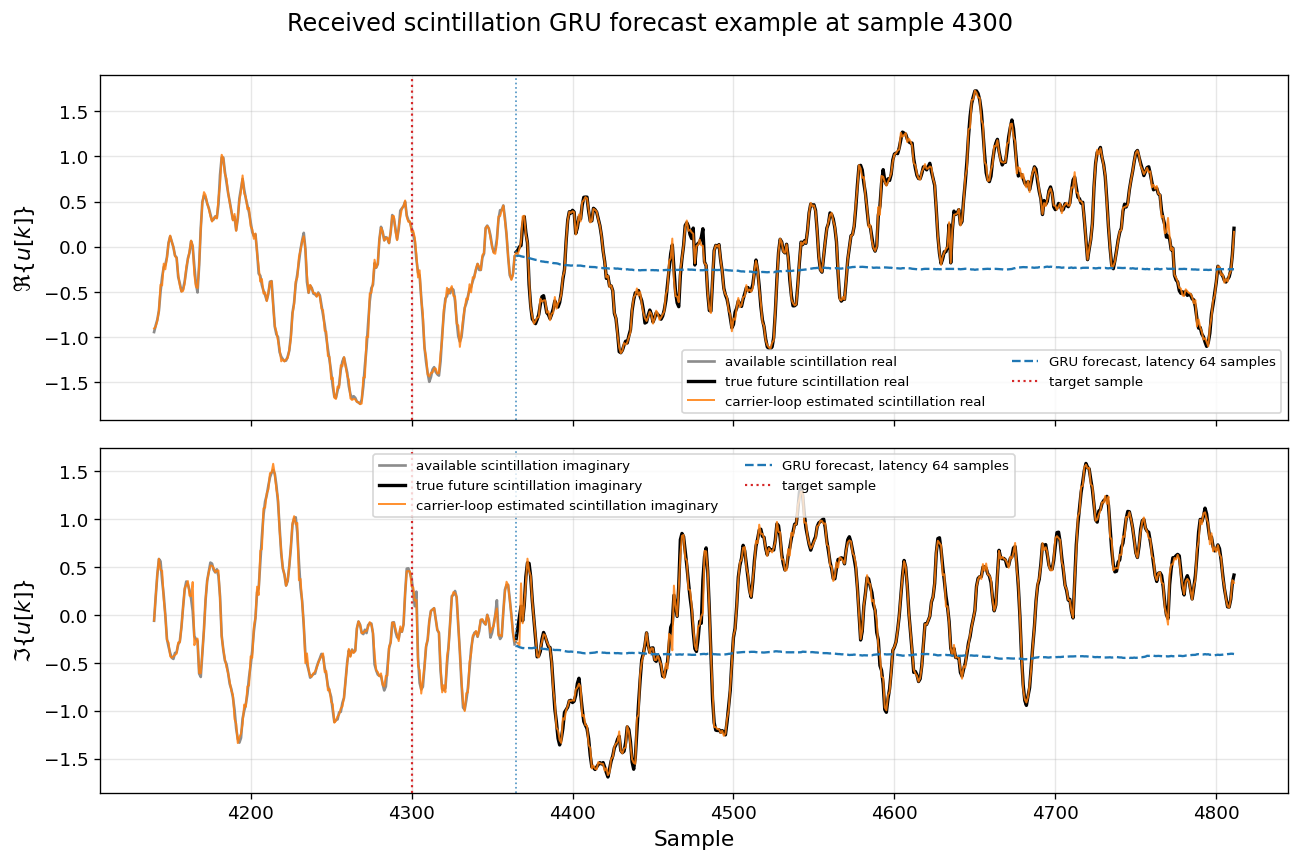

In [14]:
example_realization_idx = test_idx[0]
example_k = 4300

example_series_norm = (series[example_realization_idx] - train_mean.squeeze()) / train_std.squeeze()
example_X = example_series_norm[example_k - half : example_k + L + 1][None, :, :]
with tf.device(DEVICE):
    example_pred_norm = model.predict(example_X, verbose=0)[0]
example_anchor = series[example_realization_idx, example_k + L]
example_pred = example_anchor + example_pred_norm * train_std.squeeze()

context_start = example_k - 160
available_stop = example_k + L + 1
future_start = example_k + L + 1
future_stop = example_k + future_context + 1

context_axis = np.arange(context_start, available_stop)
future_axis = np.arange(future_start, future_stop)
tracking_axis = np.arange(context_start, future_stop)
context_values = series[example_realization_idx, context_start:available_stop]
true_future = series[example_realization_idx, future_start:future_stop]
tracking_values = tracking_scint_series[example_realization_idx, context_start:future_stop]

fig, axes = plt.subplots(2, 1, figsize=(11.0, 7.2), sharex=True)
axes[0].plot(context_axis, context_values[:, 0], color="0.55", linewidth=1.6, label="available scintillation real")
axes[0].plot(future_axis, true_future[:, 0], color="k", linewidth=2, label="true future scintillation real")
axes[0].plot(tracking_axis, tracking_values[:, 0], color="tab:orange", linewidth=1.2, alpha=0.85, label="carrier-loop estimated scintillation real")
axes[0].plot(future_axis, example_pred[:, 0], "--", color="tab:blue", linewidth=1.4, label=f"GRU forecast, latency {L} samples")

axes[1].plot(context_axis, context_values[:, 1], color="0.55", linewidth=1.6, label="available scintillation imaginary")
axes[1].plot(future_axis, true_future[:, 1], color="k", linewidth=2, label="true future scintillation imaginary")
axes[1].plot(tracking_axis, tracking_values[:, 1], color="tab:orange", linewidth=1.2, alpha=0.85, label="carrier-loop estimated scintillation imaginary")
axes[1].plot(future_axis, example_pred[:, 1], "--", color="tab:blue", linewidth=1.4, label=f"GRU forecast, latency {L} samples")

for ax in axes:
    ax.axvline(example_k, color="tab:red", linestyle=":", linewidth=1.3, label="target sample")
    ax.axvline(future_start, color="tab:blue", linestyle=":", linewidth=1.0, alpha=0.8)
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2, fontsize=8)

axes[0].set_ylabel(r"$\Re\{u[k]\}$")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel(r"$\Im\{u[k]\}$")
fig.suptitle(f"Received scintillation GRU forecast example at sample {example_k}", y=0.995)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "gru_forecast_example_with_tracking_estimate.png", dpi=300)
plt.show()
